<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/05_Transient_Couette_Flow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 5: Transient Couette Flow

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To solve unsteady plane Couette flow with the finite volume method using an explicit (FTCS) and an implicit (backward Euler) time scheme, to compare both with the exact series solution, and to study how grid size and time step affect error and stability.

## 2. Problem and parameters
Two parallel plates are a distance H apart. The lower plate is fixed and the upper plate moves with speed U. The fluid starts at rest. The flow is one-dimensional, u(y, t), with no pressure gradient.

| Parameter | Symbol | Value |
|---|---|---|
| Plate gap | H | 1.0 |
| Upper plate speed | U | 1.0 |
| Kinematic viscosity | ν | 0.02 |
| Number of cells (base case) | N | 25 |
| End time | t_end | 10 |
| Explicit Fourier number (base case) | Fo = νΔt/Δy² | 0.4 |
| Implicit time step (base case) | Δt | 0.2 (Fo = 2.5) |

Diffusion time scale H²/ν = 50, so t_end = 10 is 0.2 diffusion times: the profile is still developing.

## 3. Governing equation and method
$$\frac{\partial u}{\partial t} = \nu \frac{\partial^2 u}{\partial y^2}, \quad u(0,t)=0,\ u(H,t)=U,\ u(y,0)=0$$

The gap is divided into N cells of width Δy = H/N with unknowns at the cell centres. Integrating over a cell gives
$$\Delta y \frac{du_i}{dt} = \nu\left[\left(\frac{\partial u}{\partial y}\right)_{e} - \left(\frac{\partial u}{\partial y}\right)_{w}\right]$$
Interior faces use the central difference (u_{i+1} − u_i)/Δy. The plates lie on cell faces, so the wall cells use a half-cell distance: the wall gradient is (u_wall − u_1)/(Δy/2).

- **Explicit:** u^{n+1} = u^n + Fo (L u^n + b). Stable only if Fo ≤ 0.5.
- **Implicit:** (I − Fo L) u^{n+1} = u^n + Fo b. Stable for any Δt, with a time-step error that grows with Δt.

Here L is the matrix of the second difference (with −3 on the two wall-cell diagonals) and b holds the wall values (0 at the bottom, 2U at the top).

**Exact solution** (separation of variables):
$$u(y,t) = U\frac{y}{H} + \sum_{n=1}^{\infty}\frac{2U}{n\pi}(-1)^n \sin\left(\frac{n\pi y}{H}\right) e^{-\nu n^2\pi^2 t/H^2}$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

H, U, nu, t_end = 1.0, 1.0, 0.02, 10.0

def operator(N):
    """Matrix L and vector b so that du/dt = nu/dy^2 * (L u + b)."""
    L = np.diag(-2*np.ones(N)) + np.diag(np.ones(N-1), 1) + np.diag(np.ones(N-1), -1)
    L[0, 0] = L[-1, -1] = -3
    b = np.zeros(N)
    b[-1] = 2*U            # top wall moving, bottom wall at rest
    return L, b

def solve(N, dt, scheme, snapshots=()):
    """March to t_end. Returns u at the cell centres (and snapshots if asked)."""
    dy = H/N
    Fo = nu*dt/dy**2
    n_steps = int(round(t_end/dt))
    L, b = operator(N)
    u = np.zeros(N)
    if scheme == 'implicit':
        A = np.eye(N) - Fo*L
    snaps = {}
    snap_steps = {int(round(ts/dt)): ts for ts in snapshots}
    for n in range(1, n_steps+1):
        if scheme == 'explicit':
            u = u + Fo*(L@u + b)
        else:
            u = np.linalg.solve(A, u + Fo*b)
        if n in snap_steps:
            snaps[snap_steps[n]] = u.copy()
    return (u, snaps) if snapshots else u

def exact(y, t, terms=200):
    u = U*y/H
    for n in range(1, terms+1):
        u = u + (2*U/(n*np.pi))*(-1)**n*np.sin(n*np.pi*y/H)*np.exp(-nu*(n*np.pi/H)**2*t)
    return u

def centres(N):
    return (np.arange(N)+0.5)*H/N

## 4. Base case: explicit and implicit against the exact solution

Explicit: dt = 0.0320, Fo = 0.40, max error = 1.78e-05
Implicit: dt = 0.2000, Fo = 2.50, max error = 3.71e-03


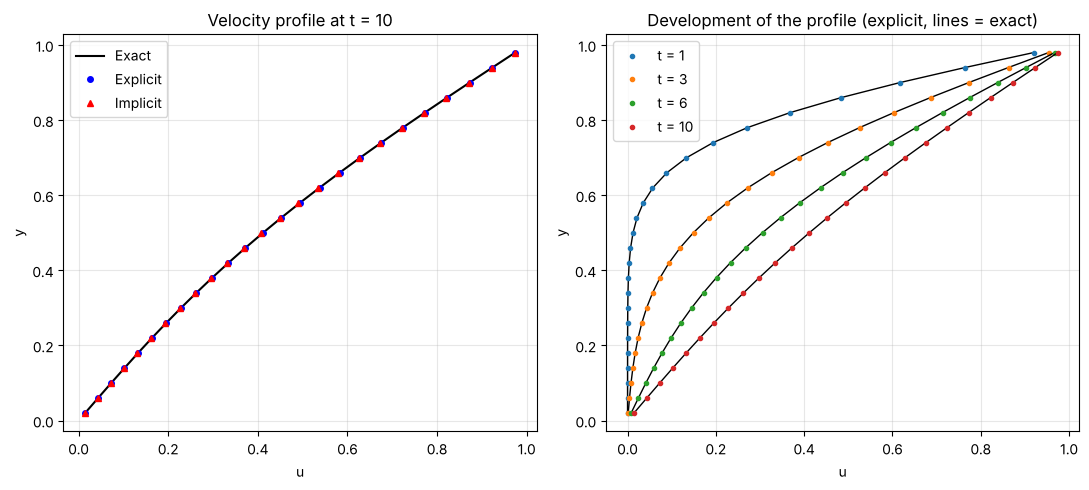

In [ ]:
N = 25
y = centres(N)
dt_exp = 0.4*(H/N)**2/nu
dt_imp = 0.2

times = (1.0, 3.0, 6.0, 10.0)
u_e, snap_e = solve(N, dt_exp, 'explicit', snapshots=times)
u_i = solve(N, dt_imp, 'implicit')
u_ex = exact(y, t_end)

print(f"Explicit: dt = {dt_exp:.4f}, Fo = {nu*dt_exp/(H/N)**2:.2f}, max error = {np.max(abs(u_e-u_ex)):.2e}")
print(f"Implicit: dt = {dt_imp:.4f}, Fo = {nu*dt_imp/(H/N)**2:.2f}, max error = {np.max(abs(u_i-u_ex)):.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].plot(u_ex, y, 'k-', label='Exact')
ax[0].plot(u_e, y, 'bo', ms=4, label='Explicit')
ax[0].plot(u_i, y, 'r^', ms=4, label='Implicit')
ax[0].set(xlabel='u', ylabel='y', title=f'Velocity profile at t = {t_end:g}')
ax[0].legend(); ax[0].grid(alpha=0.3)
for ts in times:
    ax[1].plot(exact(y, ts), y, 'k-', lw=1)
    ax[1].plot(snap_e[ts], y, 'o', ms=3, label=f't = {ts:g}')
ax[1].set(xlabel='u', ylabel='y', title='Development of the profile (explicit, lines = exact)')
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Effect of grid size (explicit, Fo = 0.4 kept fixed)

In [ ]:
rows = []
for Nc in (10, 25, 50, 100):
    dt = 0.4*(H/Nc)**2/nu
    uc = solve(Nc, dt, 'explicit')
    err = np.max(abs(uc - exact(centres(Nc), t_end)))
    rows.append([Nc, dt, int(round(t_end/dt)), err])
grid_table = pd.DataFrame(rows, columns=['N', 'dt', 'steps', 'max error'])
grid_table

,N,dt,steps,max error
0,10,0.200,50,0.001661
1,25,0.032,312,0.000018
2,50,0.008,1250,0.000066
3,100,0.002,5000,0.000016


## 6. Effect of time step (N = 25)

In [ ]:
rows = []
dy = H/25
for dt in (0.01, 0.032, 0.1, 0.2, 0.5, 1.0, 2.0):
    Fo = nu*dt/dy**2
    ui = solve(25, dt, 'implicit')
    err_i = np.max(abs(ui - exact(centres(25), t_end)))
    if Fo <= 0.5:
        ue = solve(25, dt, 'explicit')
        err_e = np.max(abs(ue - exact(centres(25), t_end)))
    else:
        ue = solve(25, dt, 'explicit')
        err_e = np.max(abs(ue))   # shown only to demonstrate blow-up
    rows.append([dt, Fo, err_e if Fo <= 0.5 else 'unstable (max|u| = %.1e)' % err_e, err_i])
dt_table = pd.DataFrame(rows, columns=['dt', 'Fo', 'explicit max error', 'implicit max error'])
dt_table

,dt,Fo,explicit max error,implicit max error
0,0.010,0.125,0.000116,0.000461
1,0.032,0.400,0.000018,0.001120
2,0.100,1.250,unstable (max|u| = 8.1e+58),0.002006
3,0.200,2.500,unstable (max|u| = 3.9e+46),0.003712
4,0.500,6.250,unstable (max|u| = 4.9e+26),0.008767
5,1.000,12.500,unstable (max|u| = 1.4e+16),0.017013
6,2.000,25.000,unstable (max|u| = 2.3e+09),0.032782


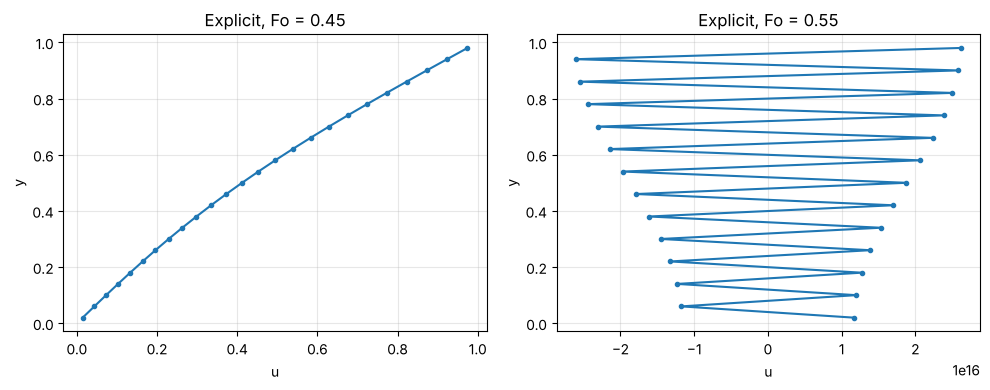

In [ ]:
# Stability demonstration: explicit scheme just below and just above Fo = 0.5
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, Fo in zip(ax, (0.45, 0.55)):
    dt = Fo*(H/25)**2/nu
    uu = solve(25, dt, 'explicit')
    a.plot(uu, centres(25), 'o-', ms=3)
    a.set(title=f'Explicit, Fo = {Fo}', xlabel='u', ylabel='y'); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()